In [1]:
%reload_ext autoreload
%autoreload 2

In [2]:
import os

os.environ['CUDA_VISIBLE_DEVICES'] = '1'
os.environ['XLA_PYTHON_CLIENT_MEM_FRACTION'] = '1'

In [3]:
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt

import statsmodels.api as sm
from scipy.odr import Model, Data, ODR

In [4]:
def flag_bad(x):
    """
    It returns True if the input is NaN or Inf, and False otherwise

    :param x: the input data
    :return: A boolean array of the same shape as x, where True indicates that the corresponding element
    of x is NaN or +/-inf.
    """
    return np.isnan(x) | np.isinf(x)


def remove_bad(xs):
    if xs[0].ndim == 1:
        n_sample = len(xs[0])
    else:
        n_sample = xs[0].shape[0]
    bad = np.zeros(n_sample, dtype=bool)
    for x in xs:
        if x.ndim == 1:
            bad |= flag_bad(x)
        else:
            bad |= flag_bad(x).any(axis=1)
    return [x[~bad] for x in xs]


def all_asarray(xs):
    return [np.asarray(x) for x in xs]


def get_linear_model(k, b):

    def func(x):
        return k * x + b

    return func


def preprocess(xs):
    '''
    allasarray + remove_bad
    '''
    return remove_bad(all_asarray(xs))

def xy2logxy(x, y, x_err, y_err):
    logx = np.log10(x)
    logy = np.log10(y)
    logx_err = x_err / (x * np.log(10))
    logy_err = y_err / (y * np.log(10))
    return logx, logy, logx_err, logy_err

def get_OLS(x, y, return_res=False):
    # y = kx + b
    x, y = preprocess([x, y])

    X = sm.add_constant(x)
    model = sm.OLS(y, X)
    results = model.fit()

    if return_res:
        return results

    b, k = results.params
    b_err, k_err = results.HC1_se

    func = get_linear_model(k, b)

    std = np.std(func(x) - y)

    return {'k': (k, k_err), 'b': (b, b_err), 'std': std, 'func': func}

def get_WLS(x, y, y_err, return_res=False):
    # y = kx + b
    x, y, y_err = preprocess([x, y, y_err])

    X = sm.add_constant(x)
    model = sm.WLS(y, X, weights=1. / np.square(y_err))
    results = model.fit()

    if return_res:
        return results

    b, k = results.params
    b_err, k_err = results.HC1_se

    func = get_linear_model(k, b)

    std = np.std(func(x) - y)

    return {'k': (k, k_err), 'b': (b, b_err), 'std': std, 'func': func}


def get_ODR(x, y, x_err=None, y_err=None, return_res=False):

    # https://docs.scipy.org/doc/scipy/reference/odr.html

    def f(B, x):
        return B[0] * x + B[1]

    if x_err is None:
        x_err = np.ones_like(x)
    if y_err is None:
        y_err = np.ones_like(y)

    x, y, x_err, y_err = preprocess([x, y, x_err, y_err])

    linear = Model(f)
    mydata = Data(x, y, wd=1. / np.square(x_err), we=1. / np.square(y_err))
    myodr = ODR(mydata, linear, beta0=[1., 0.])
    results = myodr.run()

    if return_res:
        return results

    k, b = results.beta
    k_err, b_err = results.sd_beta

    func_xy = get_linear_model(k, b)
    func_yx = get_linear_model(1 / k, -b / k)

    x_std = np.std(func_yx(y) - x)
    y_std = np.std(func_xy(x) - y)

    d_std = np.std((func_xy(x) - y) / np.sqrt(k**2 + 1))

    return {
        'k': (k, k_err),
        'b': (b, b_err),
        'x_std': x_std,
        'y_std': y_std,
        'd_std': d_std,
        'func_xy': func_xy,
        'func_yx': func_yx
    }

In [5]:
k = 1.3
b = 0.1
sig = 0.2
N = 10000

x = np.random.uniform(0.1, 10, size=N)

y = 10 ** (k * np.log10(x) + b + np.random.normal(0, sig, size=N))

x_err = np.random.uniform(0.1, 0.5, size=N)
x_obs = np.random.normal(x, x_err)

y_err = np.random.uniform(0.1, 0.5, size=N)
y_obs = np.random.normal(y, y_err)

x_err = jnp.asarray(x_err)
x_obs = jnp.asarray(x_obs)
y_err = jnp.asarray(y_err)
y_obs = jnp.asarray(y_obs)

In [6]:
logx_obs, logy_obs, logx_err, logy_err = xy2logxy(x_obs, y_obs, x_err, y_err)

/tmp/ipykernel_1510244/3205802666.py:45: RuntimeWarning: invalid value encountered in log10
  logx = np.log10(x)
/tmp/ipykernel_1510244/3205802666.py:46: RuntimeWarning: invalid value encountered in log10
  logy = np.log10(y)


In [7]:
res_ODR = get_ODR(logx_obs, logy_obs)
res_OLS = get_OLS(logx_obs, logy_obs)

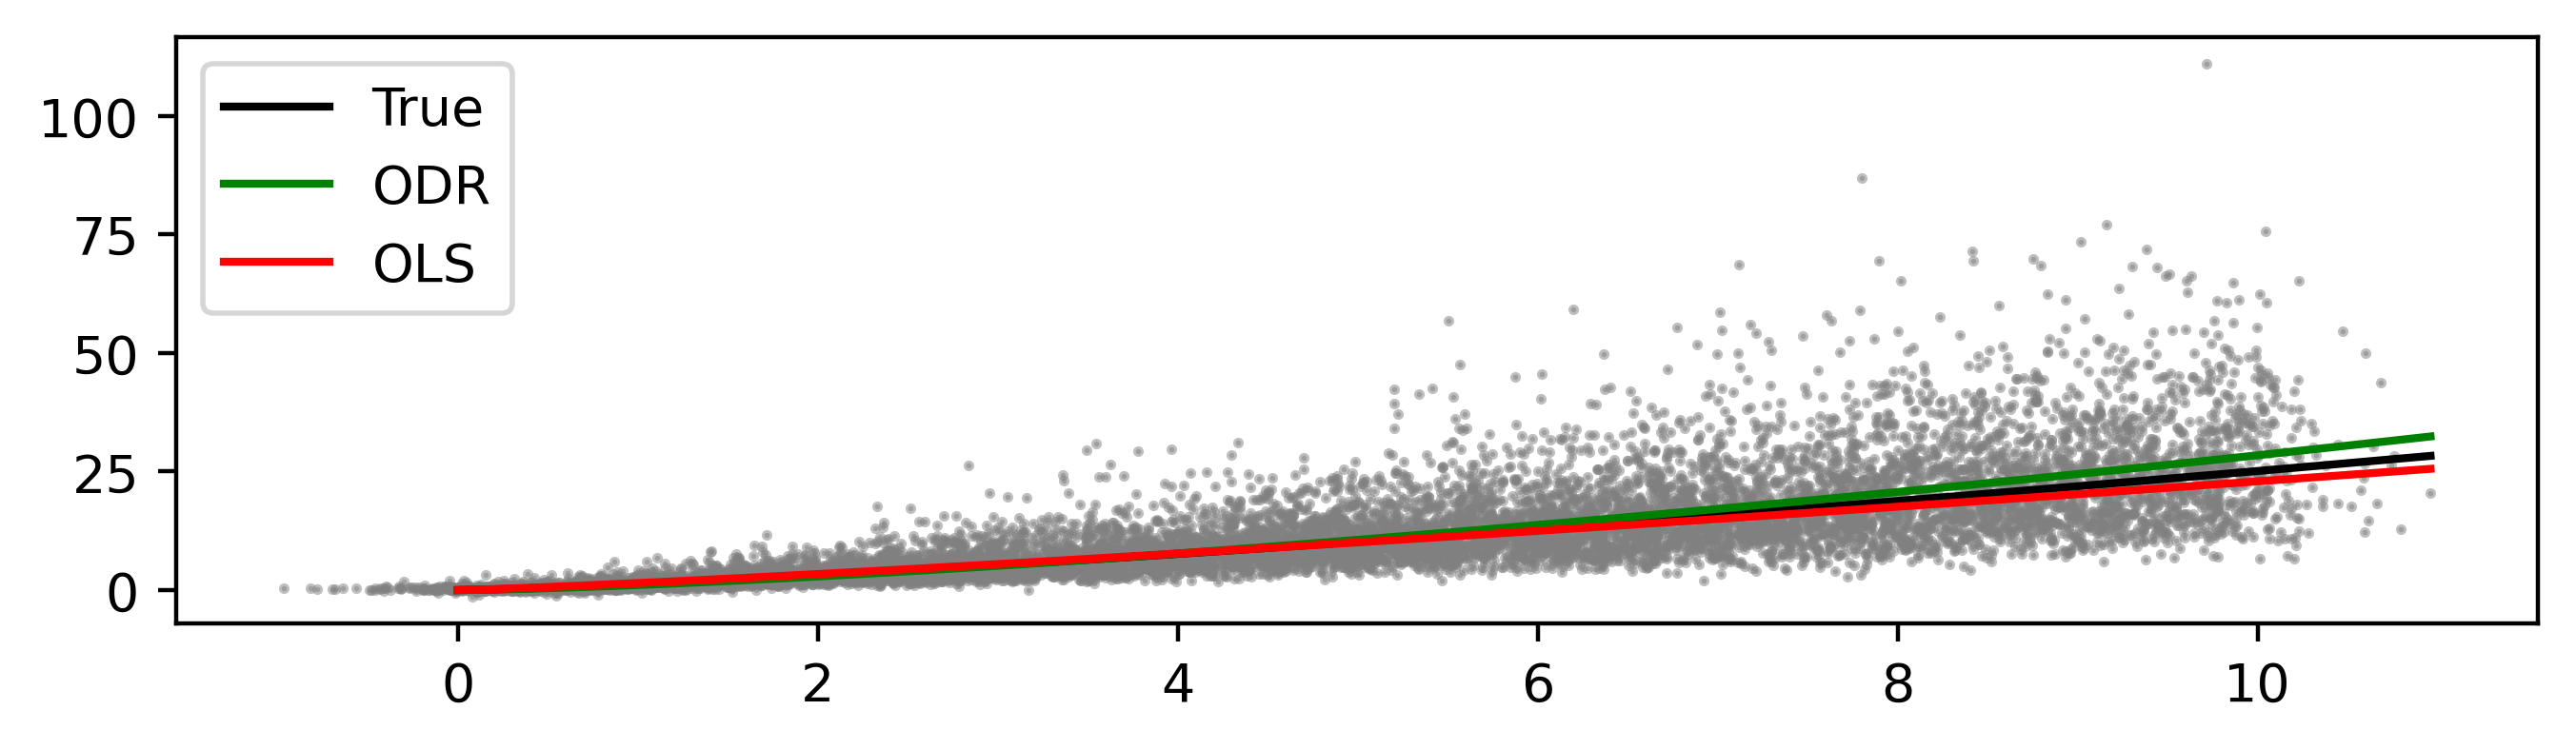

In [8]:
plt.figure(figsize=(8, 2), dpi=400)

plt.scatter(x_obs, y_obs, s=1, color='gray', alpha=0.5)
xx = np.linspace(max(1e-10, x_obs.min()), x_obs.max(), 100)
yy = 10 ** (k * np.log10(xx) + b)
yy_ODR = 10 ** res_ODR['func_xy'](np.log10(xx))
yy_OLS = 10 ** res_OLS['func'](np.log10(xx))

plt.plot(xx, yy, color='black', label='True')
plt.plot(xx, yy_ODR, color='green', label='ODR')
plt.plot(xx, yy_OLS, color='red', label='OLS')

plt.legend()

### Fit p(x, x_err) and p(y, y_err)

In [9]:
from rarden.api.fitter import FlowVI, RegressorLogLinearML, RegressorLogLinearKS
from rarden.transfer import neglogplus

In [10]:
xflow = FlowVI(x_min=0,
               x_max=x_obs.max(),
               x_err_min=0,
               x_err_max=x_err.max() * 1.2,
               transfer=neglogplus)

xflow.fit(x_obs, x_err, verbose=True)

100%|██████████| 100/100 [00:07<00:00, 12.76it/s]


step 0: loss 0.884823203086853
step 10: loss 0.8627980351448059
step 20: loss 0.8573670387268066
step 30: loss 0.8552507758140564
step 40: loss 0.8538578152656555
step 50: loss 0.8528386354446411
step 60: loss 0.8539360165596008


In [11]:
xflow.ks_test(x_obs, x_err, 10000)

(0.01459998544305563, 0.49154766720061044)

In [12]:
yflow = FlowVI(transfer=neglogplus)

yflow.fit(y_obs, y_err, verbose=True)

100%|██████████| 100/100 [00:07<00:00, 14.05it/s]


step 0: loss 2.1045749187469482
step 10: loss 2.0291836261749268
step 20: loss 2.0216681957244873
step 30: loss 2.019124984741211
step 40: loss 2.0172996520996094
step 50: loss 2.014524459838867
step 60: loss 2.0159363746643066


In [13]:
yflow.ks_test(y_obs, y_err, 10000)

(0.01574999839067459, 0.39468851358787643)

### ML Based Method

In [14]:
regressor_logLinear_ML = RegressorLogLinearML(xflow, yflow)

In [15]:
res_ML = regressor_logLinear_ML.fit(x_obs, x_err, y_obs, y_err, [1., 0., 0.1], verbose=True)

0 1.0167944 0.021924738 0.17762566 -3.141803
1000 1.2447088 0.13813217 0.20080425 -2.0515687
2000 1.2761182 0.11583883 0.20052983 -2.0499258
3000 1.286127 0.10872505 0.20051 -2.0497594
4000 1.2893451 0.10643726 0.20051023 -2.049742
5000 1.2903799 0.10570134 0.20051111 -2.04974
converged, so stop with 5000 iterations


In [16]:
print('ML fitted:', *res_ML)
print('Truth:', k, b, sig)

ML fitted: 1.2903799 0.10570134 0.20051111
Truth: 1.3 0.1 0.2


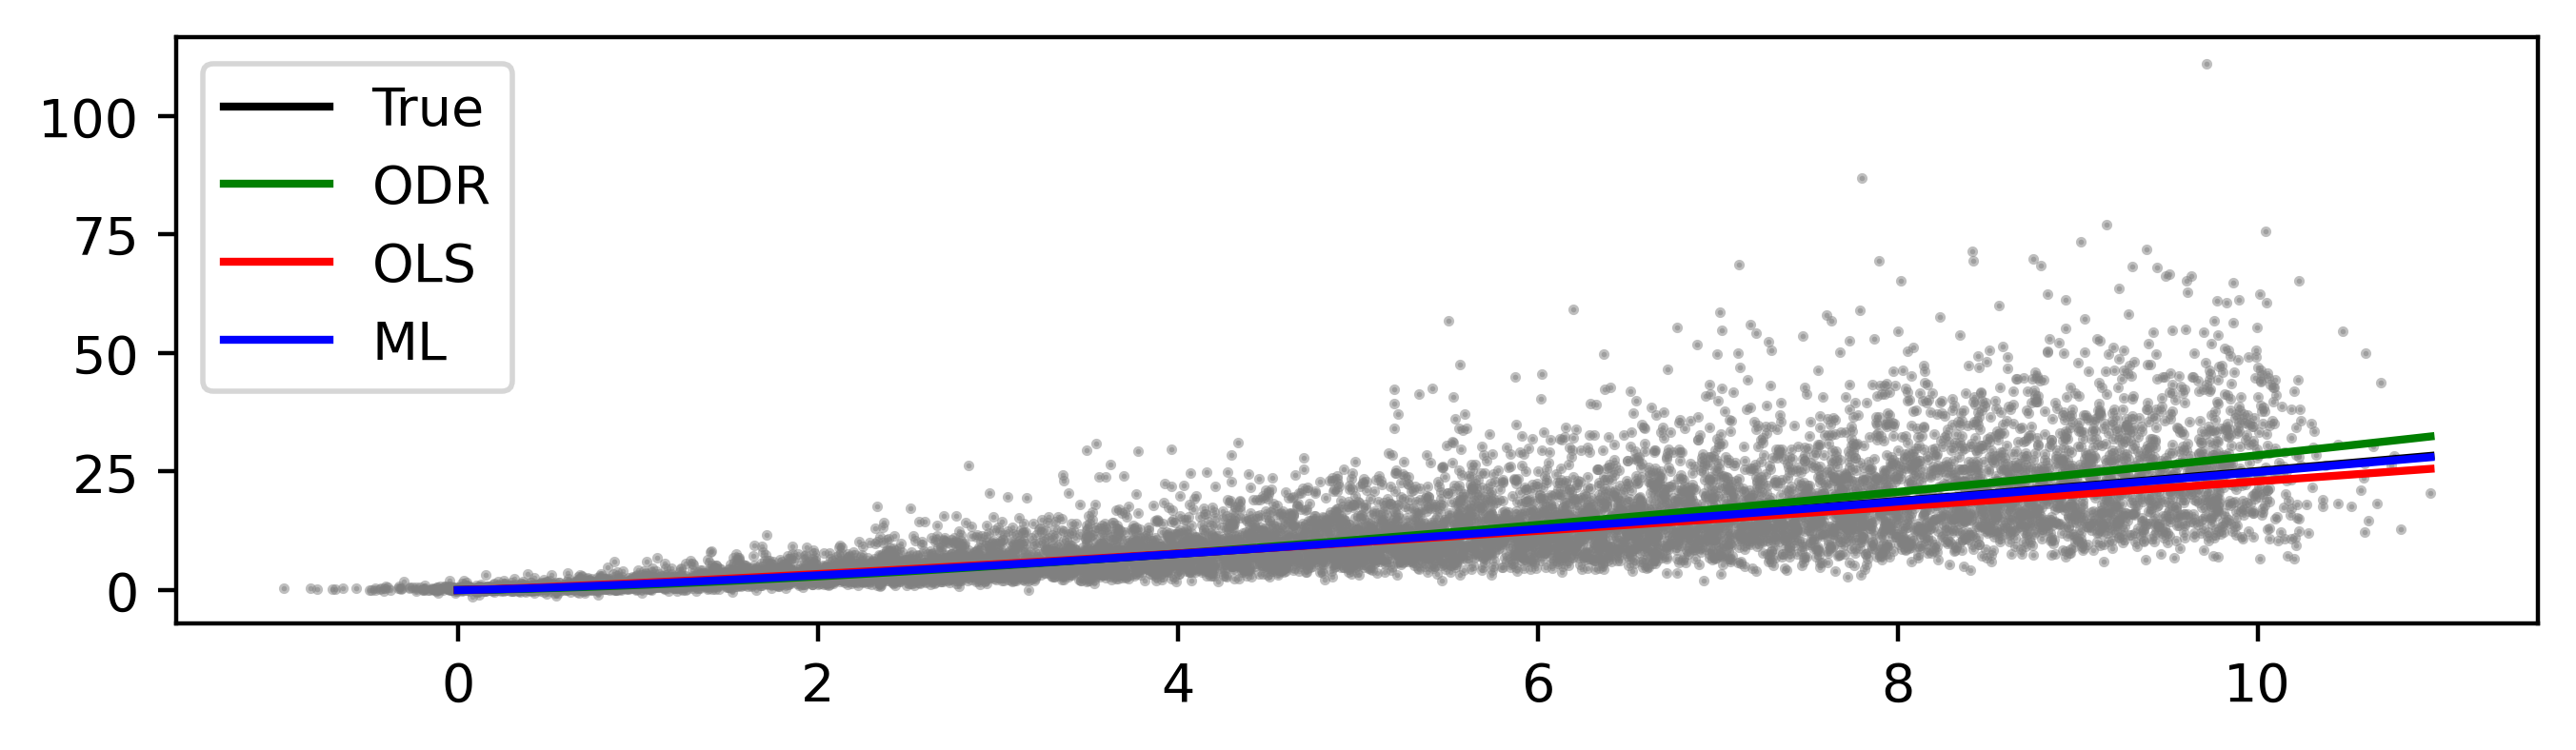

In [17]:
plt.figure(figsize=(8, 2), dpi=400)

plt.scatter(x_obs, y_obs, s=1, color='gray', alpha=0.5)
xx = np.linspace(max(1e-10, x_obs.min()), x_obs.max(), 100)
yy = 10 ** (k * np.log10(xx) + b)
yy_ODR = 10 ** res_ODR['func_xy'](np.log10(xx))
yy_OLS = 10 ** res_OLS['func'](np.log10(xx))
yy_ML = 10 ** (res_ML[0] * np.log10(xx) + res_ML[1])

plt.plot(xx, yy, color='black', label='True')
plt.plot(xx, yy_ODR, color='green', label='ODR')
plt.plot(xx, yy_OLS, color='red', label='OLS')
plt.plot(xx, yy_ML, color='blue', label='ML')

plt.legend()

In [18]:
x_obs_gen, y_obs_gen, x_err_gen, y_err_gen, x_gen, y_gen = regressor_logLinear_ML.sample(
    res_ML)

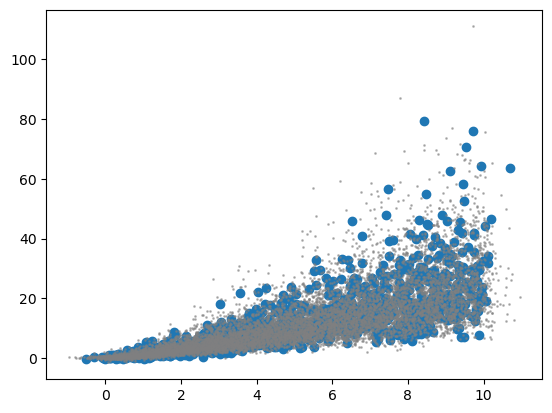

In [19]:
plt.scatter(x_obs_gen, y_obs_gen)
plt.scatter(x_obs, y_obs, s=1, color='gray', alpha=0.5)

### KS Based Method

In [20]:
regressor_logLinear_KS = RegressorLogLinearKS(xflow, yflow)

In [21]:
params_mean, params_std, res_arr = regressor_logLinear_KS.fit(
    x_obs,
    y_obs,
    params_list=[
        np.linspace(0.5, 1.5, 7),
        np.linspace(-0.1, 0.3, 7),
        np.linspace(0.1, 0.3, 5)
    ],
    verbose=True)
print(params_mean, params_std)

----
k: 1.277 +/- 0.106
b: 0.131 +/- 0.083
sig: 0.227 +/- 0.030
----
k: 1.233 +/- 0.095
b: 0.150 +/- 0.074
sig: 0.209 +/- 0.036
----
k: 1.265 +/- 0.099
b: 0.124 +/- 0.077
sig: 0.208 +/- 0.037
----
k: 1.244 +/- 0.104
b: 0.140 +/- 0.080
sig: 0.212 +/- 0.037
----
k: 1.248 +/- 0.101
b: 0.137 +/- 0.077
sig: 0.208 +/- 0.036
----
k: 1.248 +/- 0.092
b: 0.137 +/- 0.074
sig: 0.209 +/- 0.038
----
k: 1.253 +/- 0.094
b: 0.138 +/- 0.075
sig: 0.201 +/- 0.039
----
k: 1.231 +/- 0.094
b: 0.148 +/- 0.074
sig: 0.202 +/- 0.038
----
k: 1.238 +/- 0.100
b: 0.144 +/- 0.079
sig: 0.206 +/- 0.038
----
k: 1.245 +/- 0.096
b: 0.137 +/- 0.072
sig: 0.209 +/- 0.039
----
k: 1.253 +/- 0.087
b: 0.132 +/- 0.069
sig: 0.211 +/- 0.035
max iteration reached
[1.24662202 0.13816343 0.20892832] [0.09480165 0.07488015 0.03828963]


In [22]:
regressor_logLinear_KS_quantile = RegressorLogLinearKS(xflow, yflow, gen_new_grid='quantile')

In [23]:
params_mean, params_std, res_arr = regressor_logLinear_KS_quantile.fit(
    x_obs,
    y_obs,
    params_list=[
        np.linspace(0.5, 1.5, 7),
        np.linspace(-0.1, 0.3, 7),
        np.linspace(0.1, 0.3, 5)
    ],
    verbose=True)
print(params_mean, params_std)

----
k: 1.233 +/- 0.163
b: 0.155 +/- 0.116
sig: 0.220 +/- 0.029
----
k: 1.235 +/- 0.114
b: 0.151 +/- 0.090
sig: 0.214 +/- 0.038
----
k: 1.252 +/- 0.097
b: 0.135 +/- 0.075
sig: 0.212 +/- 0.037
----
k: 1.263 +/- 0.096
b: 0.127 +/- 0.077
sig: 0.211 +/- 0.038
----
k: 1.259 +/- 0.093
b: 0.130 +/- 0.075
sig: 0.213 +/- 0.039
----
k: 1.247 +/- 0.100
b: 0.141 +/- 0.078
sig: 0.212 +/- 0.038
----
k: 1.261 +/- 0.095
b: 0.129 +/- 0.077
sig: 0.211 +/- 0.036
----
k: 1.252 +/- 0.100
b: 0.136 +/- 0.078
sig: 0.214 +/- 0.038
----
k: 1.237 +/- 0.092
b: 0.147 +/- 0.072
sig: 0.211 +/- 0.037
----
k: 1.234 +/- 0.087
b: 0.148 +/- 0.070
sig: 0.212 +/- 0.036
----
k: 1.236 +/- 0.095
b: 0.145 +/- 0.074
sig: 0.217 +/- 0.040
max iteration reached
[1.24637195 0.13853644 0.21185525] [0.09395382 0.07378986 0.03664907]
